# Hoja de Trabajo 6 — Task 3: punto de no retorno en un lago
CC2017 Modelación y Simulación · Grupo 3

Modelo: $\dot x = a - b x + \dfrac{x^2}{x^2+1} = f(x;a)$, con $b = 0.52 + 0.03\,((g-1)\bmod 3)$.

In [1]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.ndimage import gaussian_filter1d
from scipy.stats import kendalltau

os.makedirs('figs', exist_ok=True)
SEED = 2025                       # semilla fija: todas las simulaciones son reproducibles

g_grupo = 3                       # número de grupo
b = 0.52 + 0.03 * ((g_grupo - 1) % 3)      # tasa de pérdida del grupo
print(f"g = {g_grupo} | b = {b:.2f}")

# --- Fórmulas del enunciado -------------------------------------------------
def f(x, a):                      # campo: xdot = a - b x + x^2/(x^2+1)
    return a - b * x + x**2 / (x**2 + 1)

def g(x):                         # carga de equilibrio: a = g(x) = b x - x^2/(x^2+1)
    return b * x - x**2 / (x**2 + 1)

def gp(x):                        # g'(x) = b - 2x/(x^2+1)^2
    return b - 2 * x / (x**2 + 1)**2

g = 3 | b = 0.58


## Task 3.1

### 3.1a  La estabilidad se decide por el signo de $g'(x^*)$

En equilibrio $f(x^*;a)=0$, es decir $a = b x^* - \frac{x^{*2}}{x^{*2}+1} = g(x^*)$. Para cualquier $x$ se cumple $f(x;a) = a - g(x)$, así que

$$\frac{\partial f}{\partial x} = -g'(x).$$

Linealizando con $y = x - x^*$: $\dot y \approx f_x(x^*;a)\,y = -g'(x^*)\,y$. La solución es $y(t)=y_0 e^{-g'(x^*)t}$, que decae si $g'(x^*)>0$ (estable) y crece si $g'(x^*)<0$ (inestable).

Con el código solo verifico con SymPy la derivada que ya se hizo a mano.

In [2]:
import sympy as sp
xs, as_, bs = sp.symbols('x a b', positive=True)
fs = as_ - bs*xs + xs**2/(xs**2 + 1)
gs = bs*xs - xs**2/(xs**2 + 1)
print("f_x + g' =", sp.simplify(sp.diff(fs, xs) + sp.diff(gs, xs)))   # 0  =>  f_x = -g'
print("g'(x)    =", sp.simplify(sp.diff(gs, xs)))

f_x + g' =

 0
g'(x)    = (b*x**4 + 2*b*x**2 + b - 2*x)/(x**4 + 2*x**2 + 1)


### 3.1b  Puntos con $g'(x)=0$, $a_{col}$ y $a_{rec}$

$g'(x)=0 \iff \dfrac{2x}{(x^2+1)^2}=b$. Se resuelve numéricamente (bisección de Brent). Como $g'>0$ para $x<x_1$, $g'<0$ en $(x_1,x_2)$ y $g'>0$ para $x>x_2$, la rama baja y la alta son estables y la intermedia es inestable. El máximo local de $g$ en $x_1$ da la carga de colapso y el mínimo local en $x_2$ la de recuperación.

In [3]:
xx = np.linspace(1e-3, 3, 30001)
sg = np.sign(gp(xx)); idx = np.where(sg[:-1] != sg[1:])[0]
x1, x2 = [brentq(gp, xx[i], xx[i+1]) for i in idx]        # x1 < x2, raíces de g'(x)=0
a_col, a_rec = g(x1), g(x2)                                # g(x1)=máximo local, g(x2)=mínimo local
print(f"x1 = {x1:.5f}  ->  a_col = g(x1) = {a_col:.5f}   (colapso: desaparece la rama de aguas claras)")
print(f"x2 = {x2:.5f}  ->  a_rec = g(x2) = {a_rec:.5f}   (recuperación: desaparece la rama turbia)")
print(f"ancho de la región biestable: a_col - a_rec = {a_col - a_rec:.5f}")

x1 = 0.37959  ->  a_col = g(x1) = 0.09422   (colapso: desaparece la rama de aguas claras)
x2 = 0.83443  ->  a_rec = g(x2) = 0.07350   (recuperación: desaparece la rama turbia)
ancho de la región biestable: a_col - a_rec = 0.02072


### 3.1c  Diagrama de equilibrios

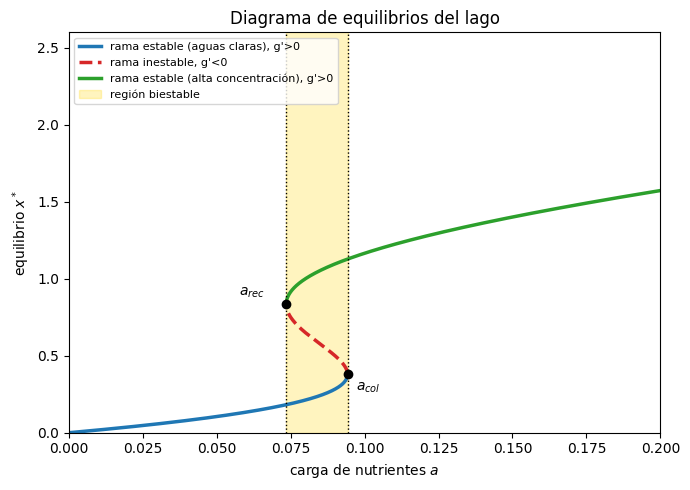

In [4]:
# Se grafica la curva paramétrica (a, x) = (g(x), x). Los tramos se colorean según el signo de g'(x).
xa = np.linspace(0, 2.6, 4000); aa = g(xa)
fig, ax = plt.subplots(figsize=(7, 5))
m1 = xa <= x1; m2 = (xa >= x1) & (xa <= x2); m3 = xa >= x2
ax.plot(aa[m1], xa[m1], 'tab:blue', lw=2.5, label="rama estable (aguas claras), g'>0")
ax.plot(aa[m2], xa[m2], 'tab:red', lw=2.5, ls='--', label="rama inestable, g'<0")
ax.plot(aa[m3], xa[m3], 'tab:green', lw=2.5, label="rama estable (alta concentración), g'>0")
ax.axvspan(a_rec, a_col, color='gold', alpha=.25, label='región biestable')
ax.axvline(a_col, color='k', ls=':', lw=1); ax.axvline(a_rec, color='k', ls=':', lw=1)
ax.scatter([a_col, a_rec], [x1, x2], c='k', zorder=5)
ax.annotate(r'$a_{col}$', (a_col, x1), textcoords='offset points', xytext=(6, -12))
ax.annotate(r'$a_{rec}$', (a_rec, x2), textcoords='offset points', xytext=(-34, 6))
ax.set_xlim(0, 0.2); ax.set_ylim(0, 2.6)
ax.set_xlabel('carga de nutrientes $a$'); ax.set_ylabel('equilibrio $x^*$'); ax.legend(fontsize=8, loc='upper left')
ax.set_title('Diagrama de equilibrios del lago'); plt.tight_layout(); plt.savefig('figs/t31_diagrama.png', dpi=150); plt.show()

### 3.1d  Barrido lento de $a$ (simulación determinista)

Se integra $\dot x = f(x;a(t))$ con Runge-Kutta 4 y $a(t)=a_0\pm\varepsilon t$. Se considera que el sistema "salta" cuando $x$ cruza el punto medio entre $x_1$ y $x_2$. Se prueban tres velocidades $\varepsilon$.

    eps  a salto (subida)   a_col  retraso subida  a salto (bajada)  a_rec  retraso bajada
0.00100           0.11780 0.09422         0.02358           0.04750 0.0735        -0.02600
0.00010           0.10029 0.09422         0.00607           0.06681 0.0735        -0.00669
0.00001           0.09566 0.09422         0.00144           0.07188 0.0735        -0.00162
cociente de retrasos entre eps consecutivos (subida): [3.88 4.22] | 10^(2/3) = 4.64


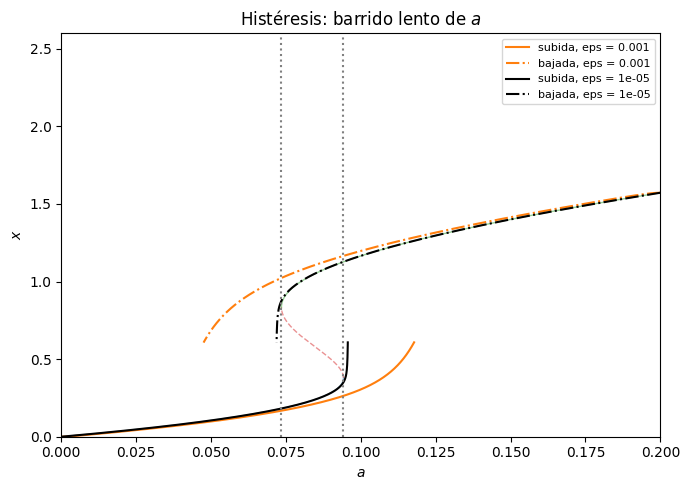

In [5]:
def rk4_scalar(x, a, h):                      # un paso de RK4 con a congelado en el paso
    k1 = f(x, a); k2 = f(x + h/2*k1, a); k3 = f(x + h/2*k2, a); k4 = f(x + h*k3, a)
    return x + h/6*(k1 + 2*k2 + 2*k3 + k4)

x_mid = 0.5 * (x1 + x2)                       # umbral de "salto"
h = 0.1
def barrido(eps, subida=True):
    # subida: a de 0 hacia arriba desde la rama baja. bajada: a de 0.2 hacia abajo desde la rama alta.
    a = 0.0 if subida else 0.2
    x = 0.0 if subida else brentq(lambda z: f(z, a), 1.0, 5.0)
    A, X = [a], [x]
    while True:
        x = rk4_scalar(x, a, h); a += (eps if subida else -eps) * h
        A.append(a); X.append(x)
        if subida and x > x_mid: break
        if (not subida) and x < x_mid: break
        if a > 0.3 or a < 0: break
    return np.array(A), np.array(X)

filas, trayect = [], {}
for eps in [1e-3, 1e-4, 1e-5]:
    Au, Xu = barrido(eps, True); Ad, Xd = barrido(eps, False)
    filas.append({'eps': eps, 'a salto (subida)': Au[-1], 'a_col': a_col, 'retraso subida': Au[-1] - a_col,
                  'a salto (bajada)': Ad[-1], 'a_rec': a_rec, 'retraso bajada': Ad[-1] - a_rec})
    trayect[eps] = (Au, Xu, Ad, Xd)
tab = pd.DataFrame(filas); print(tab.round(5).to_string(index=False))
print("cociente de retrasos entre eps consecutivos (subida):", np.round(tab['retraso subida'].values[:-1] / tab['retraso subida'].values[1:], 2),
      "| 10^(2/3) =", round(10**(2/3), 2))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(aa[m1], xa[m1], 'tab:blue', lw=1, alpha=.5); ax.plot(aa[m2], xa[m2], 'tab:red', lw=1, ls='--', alpha=.5); ax.plot(aa[m3], xa[m3], 'tab:green', lw=1, alpha=.5)
for eps, c in zip([1e-3, 1e-5], ['tab:orange', 'k']):
    Au, Xu, Ad, Xd = trayect[eps]
    ax.plot(Au, Xu, c=c, lw=1.5, label=f'subida, eps = {eps:g}'); ax.plot(Ad, Xd, c=c, lw=1.5, ls='-.', label=f'bajada, eps = {eps:g}')
ax.axvline(a_col, color='gray', ls=':'); ax.axvline(a_rec, color='gray', ls=':')
ax.set_xlim(0, 0.2); ax.set_ylim(0, 2.6); ax.set_xlabel('$a$'); ax.set_ylabel('$x$'); ax.legend(fontsize=8)
ax.set_title('Histéresis: barrido lento de $a$'); plt.tight_layout(); plt.savefig('figs/t31_histeresis.png', dpi=150); plt.show()

**Lectura.** El salto ocurre siempre un poco después de $a_{col}$ al subir y un poco antes de $a_{rec}$ al bajar. Cerca del pliegue $\dot x$ es casi cero y el sistema necesita tiempo para salir, mientras $a$ ya siguió avanzando. El retraso se achica al reducir la velocidad (aproximadamente como $\varepsilon^{2/3}$) y tiende a 0 cuando $\varepsilon\to 0$, que es el límite casi estático donde los saltos coinciden con $a_{col}$ y $a_{rec}$.

## Task 3.2

### 3.2a  Ornstein-Uhlenbeck, varianza y autocorrelación

Con ruido, $dx = f(x;a)\,dt+\sigma\,dW$. Con $x=x^*+y$ y $f(x^*;a)=0$: $f(x^*+y;a)\approx f_x(x^*)\,y=-g'(x^*)\,y=-\kappa y$, entonces

$$dy=-\kappa\,y\,dt+\sigma\,dW,\qquad \kappa=g'(x^*).$$

**Varianza.** $d(y^2)=2y\,dy+\sigma^2dt$. Tomando esperanza, $\frac{d}{dt}E[y^2]=-2\kappa E[y^2]+\sigma^2$. En estado estacionario $0=-2\kappa V+\sigma^2$, así que $V=\sigma^2/(2\kappa)$.

**Autocorrelación.** Para $\Delta t>0$, $E[y(t+\Delta t)\mid y(t)]=y(t)e^{-\kappa\Delta t}$. Multiplicando por $y(t)$ y tomando esperanza, $C(\Delta t)=V e^{-\kappa\Delta t}$, y entonces $\rho(\Delta t)=C(\Delta t)/V=e^{-\kappa\Delta t}$.

**Cuando $a\to a_{col}$:** $x^*\to x_1$ y $g'(x_1)=0$, o sea $\kappa\to0^+$. Entonces $V=\sigma^2/(2\kappa)\to\infty$ y $\rho=e^{-\kappa\Delta t}\to1$. Es la ralentización crítica: sube la varianza y sube la autocorrelación.

Comprobación numérica: se simula el proceso a $a$ fijo (sin rampa) y se compara con $\sigma^2/(2\kappa)$ y $e^{-\kappa\Delta t}$.

In [6]:
sigma, dt = 0.01, 0.05          # parámetros del enunciado
sub = 20                        # se observa cada sub*dt = 1 unidad de tiempo (retardo uno = Δt_obs = 1)
dt_obs = sub * dt

def eq_baja(a):                 # equilibrio de aguas claras: raíz de f(x;a)=0 en [0, x1]
    return brentq(lambda z: f(z, a), 0, x1)

def em(x0, a_fun, sig, nsteps, nreal, rng, sub=sub, parar_en=None):
    '''Euler-Maruyama vectorizado: x_{n+1} = x_n + f(x_n;a(t_n)) dt + sigma sqrt(dt) N(0,1).
    Guarda cada `sub` pasos. Registra el primer paso en que x > x1 (cruce del pliegue) y para cuando x > parar_en.'''
    x = np.full(nreal, float(x0)); X = np.empty((nsteps // sub + 2, nreal)); X[0] = x
    cruce = np.full(nreal, -1); vivo = np.ones(nreal, bool); nsave = 1
    for n in range(nsteps):
        x = x + f(x, a_fun(n * dt)) * dt + sig * np.sqrt(dt) * rng.standard_normal(nreal)
        c = vivo & (x > x1); cruce[c] = n + 1; vivo &= ~c               # primer cruce de x1
        if (n + 1) % sub == 0: X[nsave] = x; nsave += 1
        if parar_en is not None and (x > parar_en).all(): break      # todas las realizaciones ya saltaron
    return X[:nsave], cruce

rng = np.random.default_rng(SEED)
filas = []
for a_fijo in [0.5*a_col, 0.07, 0.085, 0.09]:
    xe = eq_baja(a_fijo); kap = gp(xe)
    X, _ = em(xe, lambda t: a_fijo, sigma, int(3000/dt), 200, rng)
    Y = X[int(100/dt_obs):] - xe                     # se descarta el transitorio inicial
    var_emp = Y.var(); ac_emp = np.mean(Y[1:] * Y[:-1]) / var_emp
    filas.append({'a': a_fijo, 'kappa=g\'(x*)': kap, 'Var teórica s^2/(2k)': sigma**2/(2*kap), 'Var simulada': var_emp,
                  'AC1 teórica e^(-k)': np.exp(-kap*dt_obs), 'AC1 simulada': ac_emp})
print(pd.DataFrame(filas).to_string(index=False, float_format=lambda v: f'{v:.4g}'))

      a  kappa=g'(x*)  Var teórica s^2/(2k)  Var simulada  AC1 teórica e^(-k)  AC1 simulada
0.04711        0.3888             0.0001286     0.0001303              0.6779        0.6779
   0.07        0.2621             0.0001907     0.0001943              0.7694        0.7727
  0.085        0.1484             0.0003369     0.0003467              0.8621        0.8746
   0.09       0.09469              0.000528     0.0005679              0.9097        0.9349


La varianza y la autocorrelación simuladas coinciden con $\sigma^2/(2\kappa)$ y $e^{-\kappa\Delta t}$. Cerca de $a_{col}$ la simulada queda un poco por encima porque la no linealidad ya no es despreciable: el sistema pasa más tiempo en valores de $x$ mayores, donde $\kappa$ es todavía más pequeño.

### 3.2b  Euler-Maruyama con carga que sube lentamente

$a(t)=a_0+\nu t$ con $a_0=0.5\,a_{col}$ y $\nu=(a_{col}-a_0)/2000$. Condición inicial: el equilibrio de aguas claras para $a_0$. Se simula hasta que $x$ pasa a la rama alta ($x>1$). Para analizar la parte anterior al salto se corta la serie en el primer instante en que $x$ supera $x_1$ (la posición del pliegue): a partir de ahí el sistema ya está saliendo del pozo de la rama baja y la linealización del inciso a no aplica.

a0 = 0.04711 | nu = 2.356e-05 | x(a0) = 0.09744


cruce de x1 en t = 2005.6  (a = 0.09435) | x > 1 (salto completo) en t = 2135.3


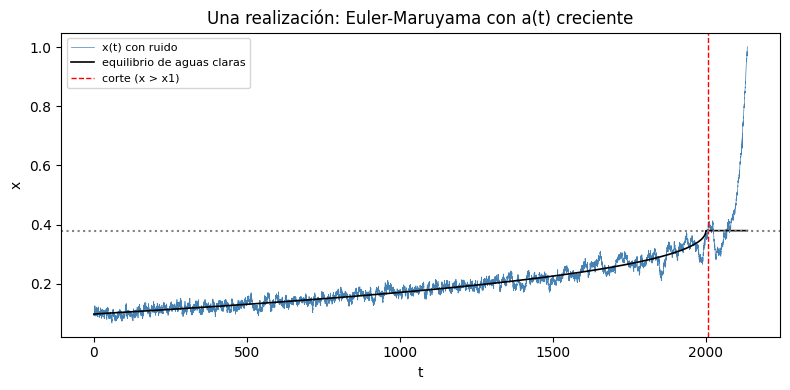

In [7]:
a0 = 0.5 * a_col
T_rampa = 2000.0
nu = (a_col - a0) / T_rampa
a_ramp = lambda t: a0 + nu * t
x_ini = eq_baja(a0)
print(f"a0 = {a0:.5f} | nu = {nu:.3e} | x(a0) = {x_ini:.5f}")

rng = np.random.default_rng(SEED + 1)
X1, cr1 = em(x_ini, a_ramp, sigma, int(4000/dt), 1, rng, sub=1, parar_en=1.0)
t1 = np.arange(len(X1)) * dt
t_cruce = cr1[0] * dt
print(f"cruce de x1 en t = {t_cruce:.1f}  (a = {a_ramp(t_cruce):.5f}) | x > 1 (salto completo) en t = {t1[-1]:.1f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t1, X1[:, 0], lw=.5, color='steelblue', label='x(t) con ruido')
ax.plot(t1, [eq_baja(min(a_ramp(t), a_col)) for t in t1], 'k', lw=1.2, label='equilibrio de aguas claras')
ax.axvline(t_cruce, color='r', ls='--', lw=1, label='corte (x > x1)'); ax.axhline(x1, color='gray', ls=':')
ax.set_xlabel('t'); ax.set_ylabel('x'); ax.legend(fontsize=8); ax.set_title('Una realización: Euler-Maruyama con a(t) creciente')
plt.tight_layout(); plt.savefig('figs/t32_serie.png', dpi=150); plt.show()

### 3.2c  Detrending y señales de alerta temprana

**Detrending.** La tendencia $x^*(a(t))$ no es lineal (se curva hacia el pliegue), por eso no sirve quitar una recta. Se usa un filtro gaussiano pasa-bajos con ancho $\sigma_{bw}=50$ unidades de tiempo y se resta. Es un método no paramétrico, no necesita conocer el modelo y el ancho es mucho mayor que el tiempo de recuperación inicial ($1/\kappa\approx2.6$), por lo que conserva las fluctuaciones rápidas. Su límite: cuando $1/\kappa$ crece cerca del colapso, parte de las fluctuaciones lentas pasan al filtro y el indicador se subestima.

**Ventana móvil.** $w=200$ observaciones (10 % del tiempo de rampa, 200 unidades de tiempo). Es suficientemente larga para estimar varianza y autocorrelación (200 datos, con tiempo de recuperación de 3 a 25 unidades) y suficientemente corta para que $a$ cambie poco dentro de la ventana ($\nu w\approx 0.0047$, cerca del 10 % de $a_{col}-a_0$), de modo que $\kappa$ varía poco en cada ventana. Más abajo se revisa la sensibilidad a $w$.

varianza: primera ventana 1.02e-04 (teoría 1.33e-04) -> última 7.01e-04 (teoría 7.56e-04)
AC1:      primera ventana 0.579 (teoría 0.686) -> última 0.932 (teoría 0.936)


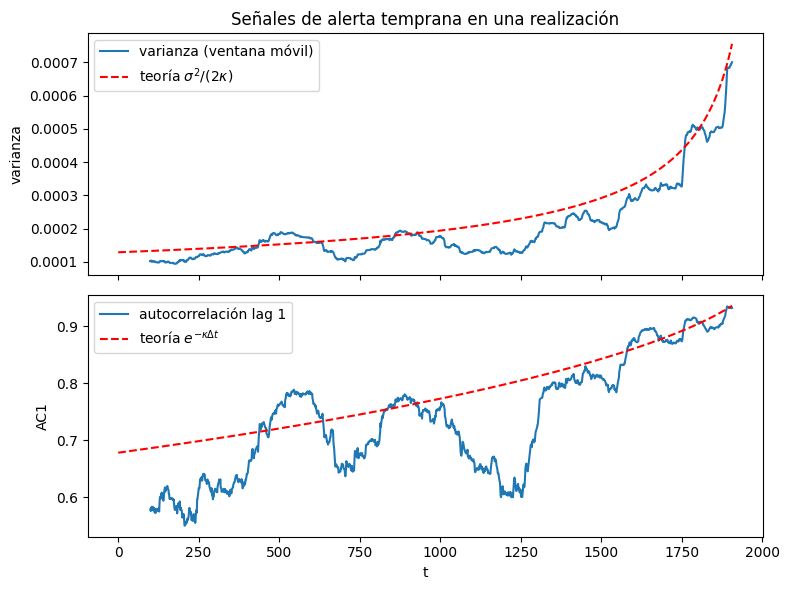

In [8]:
W, BW = 200, 50                  # tamaño de ventana (obs.) y ancho del filtro gaussiano (obs.)

def indicadores(x, w=W, bw=BW):
    # residuo = serie - tendencia (filtro gaussiano); varianza y AC1 en ventana móvil
    r = pd.Series(x - gaussian_filter1d(x, bw, mode='nearest'))
    var = r.rolling(w).var()                           # varianza de la ventana  (teoría: s^2/(2k))
    ac1 = r.rolling(w).corr(r.shift(1))                # autocorrelación de retardo 1 (teoría: e^(-k dt_obs))
    return var.values, ac1.values

def teoria(a_vals):
    kap = np.array([gp(eq_baja(min(a, a_col - 1e-9))) for a in a_vals])
    return sigma**2 / (2*kap), np.exp(-kap * dt_obs)

xs1 = X1[::sub, 0]; xs1 = xs1[: int(cr1[0] / sub) + 1]          # serie observada (Δt_obs = 1) antes del salto
v, ac = indicadores(xs1); tt = np.arange(len(xs1)) * dt_obs
tc = tt - (W - 1) / 2 * dt_obs                                   # cada valor se ubica al centro de su ventana
ok = tc >= 0; tc, v, ac = tc[ok], v[ok], ac[ok]                 # solo centros de ventana con t >= 0
v_t, ac_t = teoria(a_ramp(tc))

i0 = np.where(~np.isnan(v))[0][0]                                # primera ventana completa
print(f"varianza: primera ventana {v[i0]:.2e} (teoría {v_t[i0]:.2e}) -> última {v[-1]:.2e} (teoría {v_t[-1]:.2e})")
j0 = np.where(~np.isnan(ac))[0][0]
print(f"AC1:      primera ventana {ac[j0]:.3f} (teoría {ac_t[j0]:.3f}) -> última {ac[-1]:.3f} (teoría {ac_t[-1]:.3f})")
fig, axs = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axs[0].plot(tc, v, label='varianza (ventana móvil)'); axs[0].plot(tc, v_t, 'r--', label=r'teoría $\sigma^2/(2\kappa)$'); axs[0].set_ylabel('varianza'); axs[0].legend()
axs[1].plot(tc, ac, label='autocorrelación lag 1'); axs[1].plot(tc, ac_t, 'r--', label=r'teoría $e^{-\kappa\Delta t}$'); axs[1].set_ylabel('AC1'); axs[1].set_xlabel('t'); axs[1].legend()
axs[0].set_title('Señales de alerta temprana en una realización'); plt.tight_layout(); plt.savefig('figs/t32_indicadores.png', dpi=150); plt.show()

### 3.2d, 3.2e  100 realizaciones y control

**Tau de Kendall.** Para cada realización se calcula $\tau$ entre cada indicador y el tiempo, y se cuenta como alerta cuando $\tau>0$ y $p<0.05$. Se hace con las ventanas deslizadas de a una observación (como pide el enunciado). El test de Kendall supone datos independientes y las ventanas se solapan, así que su $p$ valor es demasiado optimista. Por eso se agrega una columna con ventanas **no solapadas** (paso = $w$), que sí son aproximadamente independientes.

In [9]:
def alerta(x, w=W, bw=BW, paso=1):
    v, a = indicadores(x, w, bw); v, a = v[w-1::paso], a[w-1::paso]
    out = []
    for s in (v, a):
        m = ~np.isnan(s); tau, p = kendalltau(np.arange(m.sum()), s[m]); out.append((tau, p))
    return out                                              # [(tau_var, p_var), (tau_ac, p_ac)]

def fracciones(series, w=W, bw=BW, paso=1):
    r = np.array([[*alerta(x, w, bw, paso)[0], *alerta(x, w, bw, paso)[1]] for x in series])
    return np.mean((r[:, 0] > 0) & (r[:, 1] < .05)), np.mean((r[:, 2] > 0) & (r[:, 3] < .05)), r

def corre(sig, T, seed, ext=2500):
    # 100 realizaciones con rampa que llega a a_col en t = T (a sigue subiendo después). Devuelve las series previas al salto.
    nu_ = (a_col - a0) / T
    X, cr = em(x_ini, lambda t: a0 + nu_ * t, sig, int((T + ext) / dt), 100, np.random.default_rng(seed), parar_en=1.0)
    ser = [X[: cr[j] // sub + 1, j] for j in range(100)]
    a_cruce = a0 + nu_ * cr * dt
    return ser, a_cruce, cr * dt

def control(sig, T, seed):
    X, _ = em(x_ini, lambda t: a0, sig, int(T / dt), 100, np.random.default_rng(seed))
    return [X[:, j] for j in range(100)]

ser, a_cr, t_cr = corre(sigma, T_rampa, SEED + 2)
ctl = control(sigma, T_rampa, SEED + 3)
print("realizaciones que cruzan x1:", int((t_cr > 0).sum()), "/ 100 | a promedio del cruce:", round(a_cr.mean(), 5), "| a_col =", round(a_col, 5))
print("longitud media de la serie previa al salto:", int(np.mean([len(s) for s in ser])), "obs.")

dv, da, R = fracciones(ser); fv, fa, Rc = fracciones(ctl)
dv2, da2, _ = fracciones(ser, paso=W); fv2, fa2, _ = fracciones(ctl, paso=W)
print(pd.DataFrame({'': ['detección (rampa)', 'falsas alarmas (control a=0.5 a_col)'],
                    'varianza (paso 1)': [dv, fv], 'AC1 (paso 1)': [da, fa],
                    'varianza (no solapadas)': [dv2, fv2], 'AC1 (no solapadas)': [da2, fa2]}).to_string(index=False))
print("tau medio (rampa): var =", R[:, 0].mean().round(3), "| AC1 =", R[:, 2].mean().round(3))
print("tau medio (control): var =", Rc[:, 0].mean().round(3), "| AC1 =", Rc[:, 2].mean().round(3))

realizaciones que cruzan x1: 100 / 100 | a promedio del cruce: 0.0938 | a_col = 0.09422
longitud media de la serie previa al salto: 1982 obs.


                                      varianza (paso 1)  AC1 (paso 1)  varianza (no solapadas)  AC1 (no solapadas)
                   detección (rampa)               1.00          1.00                     0.95                0.76
falsas alarmas (control a=0.5 a_col)               0.47          0.45                     0.02                0.01
tau medio (rampa): var = 0.669 | AC1 = 0.633
tau medio (control): var = 0.005 | AC1 = 0.001


  w det var/AC1 (paso 1) falsas var/AC1 (paso 1) det var/AC1 (no solap.) falsas var/AC1 (no solap.)
100           [1.0, 1.0]            [0.42, 0.42]            [0.99, 0.96]                [0.01, 0.0]
200           [1.0, 1.0]            [0.47, 0.45]            [0.95, 0.76]               [0.02, 0.01]
400           [1.0, 1.0]            [0.49, 0.47]             [0.21, 0.0]                 [0.0, 0.0]


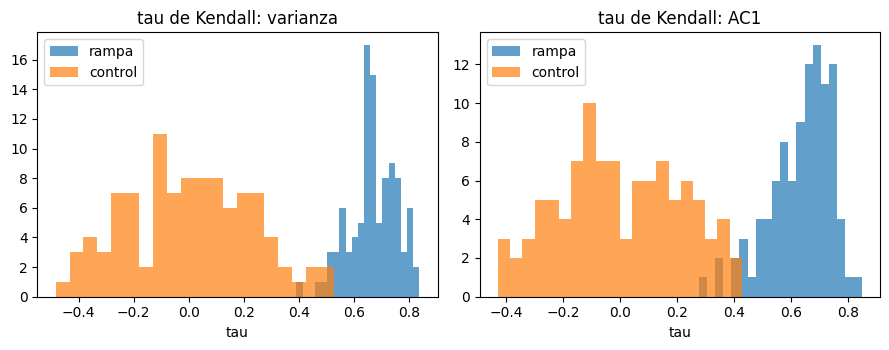

In [10]:
# Sensibilidad a la ventana (rampa vs. control, paso 1 y paso w)
filas = []
for w_ in [100, 200, 400]:
    d1 = fracciones(ser, w_, BW)[:2]; f1 = fracciones(ctl, w_, BW)[:2]
    d2 = fracciones(ser, w_, BW, paso=w_)[:2]; f2 = fracciones(ctl, w_, BW, paso=w_)[:2]
    filas.append({'w': w_, 'det var/AC1 (paso 1)': np.round(d1, 2), 'falsas var/AC1 (paso 1)': np.round(f1, 2),
                  'det var/AC1 (no solap.)': np.round(d2, 2), 'falsas var/AC1 (no solap.)': np.round(f2, 2)})
print(pd.DataFrame(filas).to_string(index=False))

fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
axs[0].hist(R[:, 0], bins=20, alpha=.7, label='rampa'); axs[0].hist(Rc[:, 0], bins=20, alpha=.7, label='control'); axs[0].set_title('tau de Kendall: varianza')
axs[1].hist(R[:, 2], bins=20, alpha=.7, label='rampa'); axs[1].hist(Rc[:, 2], bins=20, alpha=.7, label='control'); axs[1].set_title('tau de Kendall: AC1')
for a_ in axs: a_.legend(); a_.set_xlabel('tau')
plt.tight_layout(); plt.savefig('figs/t32_tau.png', dpi=150); plt.show()

**Interpretación (3.2e).** Con ventanas que se solapan, el test de Kendall marca alerta en cerca de 45 % de las series de control, que no tienen ninguna tendencia real. Los indicadores en ventanas móviles son muy autocorrelacionados y el $p$ valor supone datos independientes, por eso el 5 % nominal no se cumple. Con ventanas no solapadas la tasa de falsas alarmas baja a 1-2 % y la detección sigue siendo alta (95 % con la varianza, 76 % con la AC1). Entonces el indicador es útil como alarma solo si la prueba respeta la dependencia (ventanas no solapadas o sustitutos, como en el paper del Task 3.3). Con el Kendall ingenuo la detección de 100 % no sirve de mucho, porque el control también "detecta" casi la mitad de las veces.

### 3.2f  Duplicar $\sigma$ y reducir a la mitad el tiempo de subida

In [11]:
casos = {'base (σ=0.01, T=2000)': (sigma, 2000.0), 'σ doble (0.02)': (2*sigma, 2000.0), 'subida 2x más rápida (T=1000)': (sigma, 1000.0)}
filas, extra = [], {}
for k, (s_, T_) in casos.items():
    if k.startswith('base'): sr, acr, tcr, cc = ser, a_cr, t_cr, ctl            # mismo ensamble que 3.2d
    else: sr, acr, tcr = corre(s_, T_, SEED + 10 + len(filas)); cc = control(s_, 2000.0, SEED + 20 + len(filas))
    d = fracciones(sr, paso=1)[:2]; fa_ = fracciones(cc, paso=1)[:2]
    d2 = fracciones(sr, paso=W)[:2]; fa2_ = fracciones(cc, paso=W)[:2]
    filas.append({'caso': k, 'a medio al cruce': round(acr.mean(), 4), 'obs. previas (media)': int(np.mean([len(x) for x in sr])),
                  'det var': d[0], 'det AC1': d[1], 'falsas var': fa_[0], 'falsas AC1': fa_[1],
                  'det var (no sol.)': d2[0], 'det AC1 (no sol.)': d2[1], 'falsas var (no sol.)': fa2_[0], 'falsas AC1 (no sol.)': fa2_[1]})
    extra[k] = np.mean([x.var() for x in cc])
print(pd.DataFrame(filas).round(3).T.to_string(header=False))
print("varianza media del control:", {k: round(v_, 6) for k, v_ in extra.items()})

caso                  base (σ=0.01, T=2000)  σ doble (0.02)  subida 2x más rápida (T=1000)
a medio al cruce                      0.094           0.089                          0.095
obs. previas (media)                   1982            1771                           1012
det var                                 1.0             1.0                            1.0
det AC1                                 1.0             1.0                            1.0
falsas var                             0.47            0.54                           0.46
falsas AC1                             0.45             0.5                            0.5
det var (no sol.)                      0.95            0.72                           0.21
det AC1 (no sol.)                      0.76            0.38                            0.0
falsas var (no sol.)                   0.02            0.05                           0.03
falsas AC1 (no sol.)                   0.01            0.01                           0.02

**Explicación.**

* **σ doble.** Por el inciso a, la varianza estacionaria es $\sigma^2/(2\kappa)$, así que se multiplica por 4 en todo momento (se ve en la varianza media del control), pero la autocorrelación $e^{-\kappa\Delta t}$ no depende de $\sigma$. El tau de Kendall es un estadístico de rangos y no cambia si toda la serie se escala. Lo que sí cambia es que con más ruido las fluctuaciones sacan al sistema del pozo antes de que $a$ llegue a $a_{col}$ (el cruce ocurre con $a$ menor): la serie previa es más corta y se pierde justo el tramo final, que es donde $\kappa$ es más pequeño y la señal más clara.
* **Subida al doble de rápido.** La teoría del inciso a vale para $\kappa$ casi constante. Con $\nu$ doble, $\kappa$ cambia más dentro de cada ventana y el sistema no alcanza a estar en equilibrio local (se atrasa respecto de $x^*(a)$). Hay menos observaciones para el tramo previo (1000 en vez de 2000) y menos ventanas independientes, así que el contraste entre la parte inicial y final es menor y bajan la potencia del test y el tamaño de la tendencia.